In [1]:
from iminuit import cost, Minuit

In [12]:
from dspeed.processors import inject_gumbel
import numpy as np
import matplotlib.pyplot as plt

In [325]:
amplitude = 100
noise_std = 1
num_wfs = 100
wf_len = 32
t0_start = 12.4
width = .5

In [326]:
mean = 0
std = amplitude / signal_to_noise
empty_wfs = np.random.normal(mean, noise_std, size=(num_wfs, wf_len))
wfs = np.zeros_like(empty_wfs)
t0s = np.random.uniform(t0_start, t0_start, num_wfs)

for i in range(num_wfs):
    inject_gumbel(empty_wfs[i, :], amplitude, t0s[i], width, wfs[i, :]) 
wfs/=amplitude

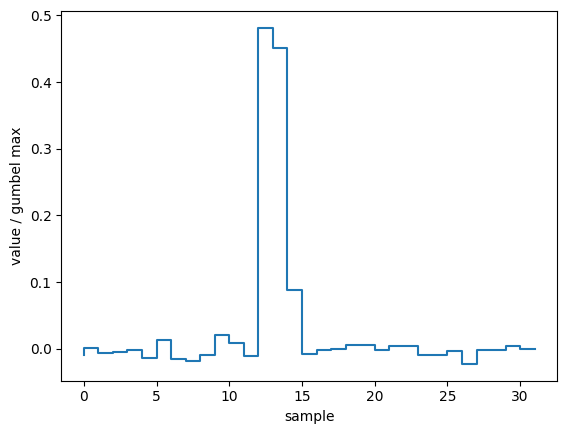

In [355]:
plt.figure()
plt.step(np.arange(0,wf_len),wfs[2])
plt.xlabel("sample")
plt.ylabel("value / gumbel max")
plt.show()

In [328]:
def gumbel(
    x,
    a,
    t0,
    beta,   
):
    start = int(np.floor(t0))
    mu = t0 + (2 * beta)
    end = int(np.ceil(mu + (8 * beta)))

    # Ensure the range is within valid waveform boundaries.
    if start < 0:
        start = 0
    if end > len(x):
        end = len(x)
    wf_out = np.zeros(len(x))
    # Loop through the specified range and add the Gumbel distribution to wf_out.
    for i in range(start, end):
        z = (i - mu) / beta
        wf_out[i] += (a / beta) * np.exp(-(z + np.exp(-z)))
    #print(np.array([0,*np.cumsum(wf_out)]))
    return wf_out

In [345]:
class LeastSquares:
    """
    Generic least-squares cost function with error.
    """

    errordef = Minuit.LEAST_SQUARES  # for Minuit to compute errors correctly

    def __init__(self, x, y):
        self.model = gumbel  # model predicts y for given x
        self.x = np.asarray(x)
        self.y = np.asarray(y)

    def __call__(self, *par):  # we must accept a variable number of model parameters
        ym = self.model(self.x, *par)
        return np.sum((self.y - ym) ** 2 / self.y)

In [349]:
class BetterLeastSquares(LeastSquares):
    def __init__(self, x, y):
        super().__init__(x, y)
        pars = describe(gumbel, annotations=True)
        model_args = iter(pars)
        next(model_args)
        self._parameters = {k: pars[k] for k in model_args}

In [350]:
from iminuit.util import describe
from typing import Annotated

## Do fit

In [351]:
#co = cost.BinnedNLL(wfs[0],np.arange(-0.5, wf_len+0.5), gumbel)
co = BetterLeastSquares(np.arange(wf_len),wfs[0])
#co = cost.LeastSquares(np.arange(wf_len),wfs[0], np.sqrt(np.abs(wfs[0])), gumbel)
m = Minuit(co, *[1, 12.4, .5])
for fix in ["beta", "t0"]:
    m.fixed[fix] = True
m.limits["a"] = (0,None)

In [352]:
m.simplex().migrad()
m.hesse()

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -0.03086                   │              Nfcn = 25               │
│ EDM = 1.01e-14 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ a    │    1.0    │    0.9    │            │            │    0    │         │       │
│ 1 │ t0   │   12.40   │   0.12    │            │            │         │         │  yes  │
│ 2 │ beta │   0.500   │   0.005   │            │            │         │         │  yes  │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────┬───────────────────┐
│      │     a    t0  beta │
├──────┼───────────────────┤
│    a │ 0.983     0     0 │
│   t0 │     0     0     0 │
│ beta │     0     0     0 │
└──────┴───────────────────┘

## Error Contour on amplitude

(<Figure size 640x480 with 1 Axes>,
 array([[<Axes: xlabel='a'>]], dtype=object))

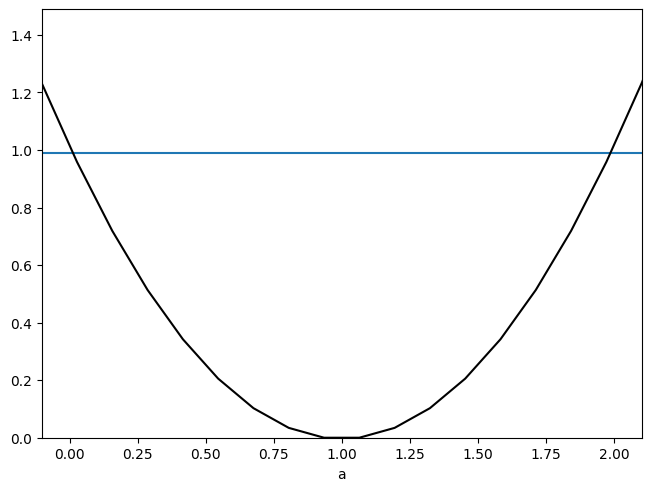

In [353]:
m.draw_mnmatrix()

## Plot Fit

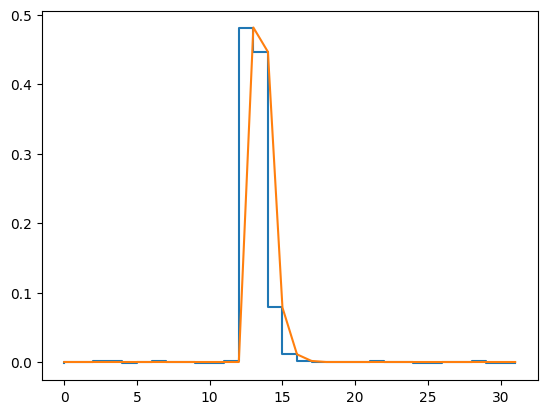

In [312]:
plt.figure()
plt.step(np.arange(0,wf_len),wfs[0])
plt.plot(np.arange(0,wf_len), gumbel(
    np.arange(0,wf_len),
    m.values["a"],
    m.values["t0"],
    m.values["beta"],   
))
plt.show()

## Plot error contour of fit

In [313]:
rng = np.random.default_rng(1)

par_b = rng.multivariate_normal(m.values, m.covariance, size=1000)

# standard deviation of bootstrapped curves
y_b = [gumbel(np.arange(0,wf_len), p[0], p[1], p[2]) for p in par_b]
yerr_boot = np.std(y_b, axis=0)

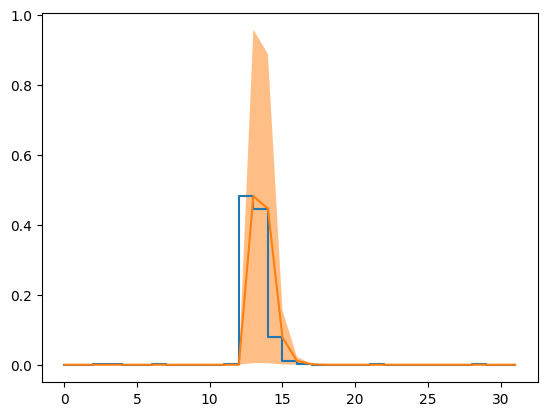

In [314]:
plt.figure()
cx = np.arange(0,wf_len)
y = gumbel(
    cx,
    m.values["a"],
    m.values["t0"],
    m.values["beta"],   
)




plt.step(cx,wfs[0])
plt.plot(cx, y)
plt.fill_between(cx, y - yerr_boot, y + yerr_boot, facecolor="C1", alpha=0.5)
plt.show()